## 1. Import Required Libraries

In [1]:
import os
import cv2
import torch
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

print("All libraries imported successfully")
print(f"PyTorch version: {torch.__version__}")
print(f"Segmentation Models PyTorch version: {smp.__version__}")

All libraries imported successfully
PyTorch version: 2.7.1
Segmentation Models PyTorch version: 0.5.0


## 2. Configuration and Hyperparameters

In [ ]:
# =============================================================================
# DEVICE CONFIGURATION
# =============================================================================
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using device: {DEVICE}")

# MPS-specific settings
if DEVICE == "mps":
    # Enable optimizations for MPS
    torch.backends.mps.allow_tf32 = True
    print("MPS optimizations enabled")

# =============================================================================
# DATA PATHS
# =============================================================================
PROCESSED_IMG_DIR = '../processed_data/images'
PROCESSED_MSK_DIR = '../processed_data/masks'
MODEL_SAVE_DIR = '../models'
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

# =============================================================================
# DATASET CLASS VALUES
# =============================================================================
POWERLINE_CHANNEL = 0  # Red channel for power line detection (gray = equal RGB)
POWERLINE_PIXEL_VAL = 110  # Gray value for power line detection

# =============================================================================
# SHARED TRAINING HYPERPARAMETERS
# =============================================================================
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256
TRAIN_TEST_SPLIT_RATIO = 0.2
RANDOM_SEED = 42

# =============================================================================
# MPS-OPTIMIZED POWER LINE MODEL CONFIGURATION
# =============================================================================
PL_ENCODER = "resnet34"  # Good performance on MPS
PL_ARCHITECTURE = "DeepLabV3"

# MPS-optimized batch sizes and settings
PL_BATCH_SIZE = 16  # Reduced for MPS + DeepLabV3 memory efficiency
PL_NUM_EPOCHS = 5
PL_LEARNING_RATE = 0.0001
PL_WEIGHT_DECAY = 0.00001
print("Using MPS-optimized settings")


# Tversky loss parameters
TVERSKY_ALPHA = 0.3  # Weight for false positives
TVERSKY_BETA = 0.7   # Weight for false negatives (higher to reduce missed detections)

print(f"\nPower Line Model Configuration:")
print(f"{PL_ARCHITECTURE}+{PL_ENCODER}, Batch={PL_BATCH_SIZE}, Max Epochs={PL_NUM_EPOCHS}")
print(f"Initial LR={PL_LEARNING_RATE}, Weight Decay={PL_WEIGHT_DECAY}")
print(f"Tversky Loss: α={TVERSKY_ALPHA}, β={TVERSKY_BETA} (reduces missed power line detections)")

Using device: mps
MPS optimizations enabled
Using MPS-optimized settings

Power Line Model Configuration:
DeepLabV3+resnet34, Batch=16, Max Epochs=5
Initial LR=0.0001, Weight Decay=1e-05
Tversky Loss: α=0.3, β=0.7 (reduces missed power line detections)


## 3. Custom Loss Function - Tversky Loss

In [3]:
class TverskyLoss(nn.Module):
    """
    Improved Tversky Loss function for imbalanced segmentation tasks.
    
    The Tversky index is a generalization of the Dice coefficient that allows
    for different weightings of false positives and false negatives.
    
    Args:
        alpha (float): Weight for false positives
        beta (float): Weight for false negatives  
        smooth (float): Smoothing factor to avoid division by zero
    """
    def __init__(self, alpha=0.5, beta=0.5, smooth=1e-6):
        super(TverskyLoss, self).__init__()
        self.alpha = alpha
        self.beta = beta
        self.smooth = smooth

    def forward(self, inputs, targets):
        # Apply sigmoid to convert logits to probabilities
        inputs = torch.sigmoid(inputs)
        
        # Flatten tensors for easier computation
        inputs = inputs.view(-1)
        targets = targets.view(-1)
        
        # Calculate True Positives, False Positives & False Negatives
        TP = (inputs * targets).sum()    
        FP = ((1-targets) * inputs).sum()
        FN = (targets * (1-inputs)).sum()
       
        # Calculate Tversky index with improved numerical stability
        denominator = TP + self.alpha*FP + self.beta*FN + self.smooth
        Tversky = (TP + self.smooth) / denominator
        
        # Add focal loss component for extreme class imbalance
        focal_weight = torch.pow(1 - Tversky, 2)  # Focus on hard examples
        
        # Return weighted Tversky loss
        return focal_weight * (1 - Tversky)

class CombinedLoss(nn.Module):
    """
    Combined loss for extreme class imbalance in power line detection.
    Combines Tversky loss with weighted BCE for better convergence.
    """
    def __init__(self, tversky_weight=0.7, bce_weight=0.3, pos_weight=10.0):
        super(CombinedLoss, self).__init__()
        self.tversky_weight = tversky_weight
        self.bce_weight = bce_weight
        self.tversky_loss = TverskyLoss(alpha=TVERSKY_ALPHA, beta=TVERSKY_BETA)
        self.bce_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight))
    
    def forward(self, inputs, targets):
        tversky = self.tversky_loss(inputs, targets)
        bce = self.bce_loss(inputs, targets)
        return self.tversky_weight * tversky + self.bce_weight * bce

print("Improved loss functions defined successfully")
print(f"Combined loss: {70}% Tversky + {30}% Weighted BCE")
print(f"Focal Tversky with alpha={TVERSKY_ALPHA}, beta={TVERSKY_BETA}")
print("Positive class weight=10x to handle severe class imbalance")

Improved loss functions defined successfully
Combined loss: 70% Tversky + 30% Weighted BCE
Focal Tversky with alpha=0.3, beta=0.7
Positive class weight=10x to handle severe class imbalance


## 4. Custom Dataset Class for Power Line Segmentation

In [4]:
class VEPLPowerLineDataset(Dataset):
    """
    Custom Dataset class for VEPL power line segmentation.
    Converts multi-class masks to binary power line masks.
    """
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]
        
        # Load RGB image and convert from BGR to RGB
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # Load mask without any color space conversion
        mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
        
        # Create binary mask for power lines (gray pixels)
        binary_mask = (mask[:, :, 0] == POWERLINE_PIXEL_VAL).astype(np.float32)
        binary_mask = np.expand_dims(binary_mask, axis=-1)

        # Apply transformations if provided
        if self.transform:
            augmented = self.transform(image=image, mask=binary_mask)
            image = augmented['image']
            binary_mask = augmented['mask']
            binary_mask = binary_mask.permute(2, 0, 1)

        return image, binary_mask

print("VEPLPowerLineDataset class defined successfully")

VEPLPowerLineDataset class defined successfully


## 5. Training and Evaluation Functions

In [5]:
def train_fn(loader, model, optimizer, loss_fn, scaler=None):
    """
    MPS-compatible training function for one epoch.
    """
    model.train()
    loop = tqdm(loader, desc="Training Power Line Model")
    total_loss = 0.0
    num_batches = len(loader)
    
    # Device-specific AMP settings
    use_amp = (DEVICE == "cuda")  # Only use AMP on CUDA
    
    for batch_idx, (data, targets) in enumerate(loop):
        data = data.to(device=DEVICE, non_blocking=True)
        targets = targets.float().to(device=DEVICE, non_blocking=True)
        
        # Skip batches that are too small for BatchNorm
        if data.size(0) < 2:
            print(f"Skipping batch {batch_idx} with size {data.size(0)}")
            continue

        # Forward pass with device-specific AMP
        if use_amp and scaler is not None:
            with torch.autocast(device_type="cuda", enabled=True):
                predictions = model(data)
                loss = loss_fn(predictions, targets)
        else:
            # No AMP for MPS/CPU
            predictions = model(data)
            loss = loss_fn(predictions, targets)
        
        total_loss += loss.item()

        # Backward pass with device-specific handling
        optimizer.zero_grad()
        
        if use_amp and scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        
        # Reduce MPS memory management frequency
        if DEVICE == "mps" and batch_idx % 50 == 0:
            torch.mps.empty_cache()

        loop.set_postfix({
            'loss': f'{loss.item():.4f}',
            'avg_loss': f'{total_loss/(batch_idx+1):.4f}'
        })
        
    return total_loss / num_batches


def check_accuracy(loader, model, device):
    """
    MPS-compatible evaluation function with NaN-safe IoU calculation.
    """
    model.eval()
    num_correct = 0
    num_pixels = 0
    dice_score = 0
    iou_score = 0
    valid_batches = 0

    with torch.no_grad():
        for batch_idx, (x, y) in enumerate(loader):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            
            if x.size(0) < 1:
                continue
            
            preds = torch.sigmoid(model(x))
            preds = (preds > 0.5).float()
            
            num_correct += (preds == y).sum()
            num_pixels += torch.numel(preds)
            
            tp, fp, fn, tn = smp.metrics.get_stats(preds.long(), y.long(), mode='binary')
            batch_iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction="micro")
            batch_dice = smp.metrics.f1_score(tp, fp, fn, tn, reduction="micro")
            
            # Only add valid (non-NaN) scores
            if not torch.isnan(batch_iou):
                iou_score += batch_iou
                valid_batches += 1
            if not torch.isnan(batch_dice):
                dice_score += batch_dice
            
            # Reduce MPS memory management frequency
            if DEVICE == "mps" and batch_idx % 50 == 0:
                torch.mps.empty_cache()

    # Handle case where all IoU values are NaN
    if valid_batches > 0:
        iou = iou_score / valid_batches
    else:
        iou = torch.tensor(0.0)
        print("Warning: All IoU calculations returned NaN. Model predicting all background.")
    
    dice = dice_score / len(loader)
    acc = num_correct / num_pixels * 100
    
    print(f"Validation: IoU Score: {iou:.4f} | Dice Score: {dice:.4f} | Pixel Accuracy: {acc:.2f}% | Valid batches: {valid_batches}/{len(loader)}")

    model.train()
    return iou.item()

print("Optimized MPS-compatible training and evaluation functions defined successfully")

Optimized MPS-compatible training and evaluation functions defined successfully


## 6. Data Loading and Preparation

In [6]:
# Load all processed tile paths
print("Loading processed data...")

all_image_paths = sorted([os.path.join(PROCESSED_IMG_DIR, f) for f in os.listdir(PROCESSED_IMG_DIR) if f.endswith('.png')])
all_mask_paths = sorted([os.path.join(PROCESSED_MSK_DIR, f) for f in os.listdir(PROCESSED_MSK_DIR) if f.endswith('.png')])

print(f"Found {len(all_image_paths)} image tiles")
print(f"Found {len(all_mask_paths)} mask tiles")

assert len(all_image_paths) == len(all_mask_paths), f"Mismatch: {len(all_image_paths)} images vs {len(all_mask_paths)} masks"
print("Image and mask counts match")

# Split data (60% train, 20% validation, 20% test)
train_val_imgs, test_imgs, train_val_msks, test_msks = train_test_split(
    all_image_paths, all_mask_paths, 
    test_size=0.2, 
    random_state=RANDOM_SEED
)

train_imgs, val_imgs, train_msks, val_msks = train_test_split(
    train_val_imgs, train_val_msks,
    test_size=0.25,
    random_state=RANDOM_SEED
)

print(f"\nData split completed:")
print(f"Training samples: {len(train_imgs)} ({len(train_imgs)/len(all_image_paths)*100:.1f}%)")
print(f"Validation samples: {len(val_imgs)} ({len(val_imgs)/len(all_image_paths)*100:.1f}%)")
print(f"Test samples: {len(test_imgs)} ({len(test_imgs)/len(all_image_paths)*100:.1f}%)")

Loading processed data...
Found 22736 image tiles
Found 22736 mask tiles
Image and mask counts match

Data split completed:
Training samples: 13641 (60.0%)
Validation samples: 4547 (20.0%)
Test samples: 4548 (20.0%)


## 7. Data Augmentation for Power Line Detection

In [7]:
print("Defining power line-specific data augmentation...")

# Power line model augmentation (geometric augmentations optimal for linear structures)
train_transform = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    
    # Geometric augmentations - important for power line detection
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.5),  # Good for power lines at different orientations
    A.Rotate(limit=15, p=0.5),  # Small rotations
    
    # Spectral augmentations - minimal for power line detection
    A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05, p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.2),
    
    # Normalization - ImageNet stats for pretrained ResNet34
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], max_pixel_value=255.0),
    ToTensorV2(),
])

# Validation transform (no augmentation)
val_transform = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], max_pixel_value=255.0),
    ToTensorV2(),
])

print("Power line augmentation strategy includes:")
print("- Geometric: Horizontal/Vertical flip, 90° rotations, small rotations")
print("- Spectral: Minimal brightness/contrast adjustments")
print("- Normalization: ImageNet stats for ResNet34 pretrained weights")

Defining power line-specific data augmentation...
Power line augmentation strategy includes:
- Geometric: Horizontal/Vertical flip, 90° rotations, small rotations
- Spectral: Minimal brightness/contrast adjustments
- Normalization: ImageNet stats for ResNet34 pretrained weights


## 8. Initialize Power Line Model

In [8]:
# # =============================================================================
# # MPS-OPTIMIZED POWER LINE MODEL CONFIGURATION  
# # =============================================================================
# PL_ENCODER = "resnet34"  # Good performance on MPS
# PL_ARCHITECTURE = "DeepLabV3"

# # Improved batch size and epochs for better training
# PL_BATCH_SIZE = 8  # Smaller batch for MPS stability
# PL_NUM_EPOCHS = 15  # More epochs for convergence
# PL_LEARNING_RATE = 0.001  # Higher initial LR
# PL_WEIGHT_DECAY = 1e-4  # Add weight decay for regularization

print("Using improved MPS-optimized settings")
print(f"Increased epochs to {PL_NUM_EPOCHS} for better convergence")
print(f"Reduced batch size to {PL_BATCH_SIZE} for MPS stability")

print("\\n" + "="*70)
print("MPS-OPTIMIZED POWER LINE SEGMENTATION MODEL TRAINING")
print("="*70)

# Initialize power line model with device-optimized settings
print(f"Initializing {PL_ARCHITECTURE} model with {PL_ENCODER} encoder...")
model = smp.DeepLabV3(
    encoder_name=PL_ENCODER,
    encoder_weights="imagenet",  # Pre-trained on ImageNet
    in_channels=3,
    classes=1,
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {total_params:,} total, {trainable_params:,} trainable")

# Use improved combined loss function
loss_fn = CombinedLoss(tversky_weight=0.7, bce_weight=0.3, pos_weight=15.0)

# MPS-optimized optimizer settings
if DEVICE == "mps":
    optimizer = optim.AdamW(model.parameters(), lr=PL_LEARNING_RATE, weight_decay=PL_WEIGHT_DECAY)
    print("Using AdamW optimizer (better for MPS)")
else:
    optimizer = optim.Adam(model.parameters(), lr=PL_LEARNING_RATE, weight_decay=PL_WEIGHT_DECAY)
    print("Using Adam optimizer")

print(f"Using Combined loss (70% Focal Tversky + 30% Weighted BCE)")
print(f"Learning Rate: {PL_LEARNING_RATE}, Weight Decay: {PL_WEIGHT_DECAY}")

# Add Learning Rate Scheduler
from torch.optim.lr_scheduler import ReduceLROnPlateau
scheduler = ReduceLROnPlateau(
    optimizer, 
    mode='max',  # Maximize IoU
    factor=0.5,  # Multiply LR by 0.5 when reducing
    patience=3,  # Reduced patience for faster adaptation
    min_lr=1e-6,  # Minimum learning rate
)
print("Learning Rate Scheduler: ReduceLROnPlateau (patience=3, factor=0.5)")

# Initialize gradient scaler only for CUDA
scaler = None
if DEVICE == "cuda":
    scaler = torch.cuda.amp.GradScaler()
    print("CUDA AMP GradScaler initialized")
elif DEVICE == "mps":
    print("MPS: Using native precision (no AMP)")
else:
    print("CPU: Using native precision")

# Create MPS-optimized data loaders
print("\\nCreating MPS-optimized data loaders...")

# MPS-specific DataLoader settings
num_workers = 0  # MPS works best with num_workers=0
pin_memory = False  # MPS doesn't benefit from pin_memory

train_loader = DataLoader(
    VEPLPowerLineDataset(train_imgs, train_msks, transform=train_transform),
    batch_size=PL_BATCH_SIZE, 
    shuffle=True, 
    num_workers=num_workers, 
    drop_last=True,
    pin_memory=pin_memory
)
val_loader = DataLoader(
    VEPLPowerLineDataset(val_imgs, val_msks, transform=val_transform),
    batch_size=PL_BATCH_SIZE, 
    shuffle=False, 
    num_workers=num_workers, 
    drop_last=False,
    pin_memory=pin_memory
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

# MPS memory management
if DEVICE == "mps":
    torch.mps.empty_cache()
    print("MPS cache cleared and ready for training")

print(f"\\nReady to train improved power line model for up to {PL_NUM_EPOCHS} epochs")
print("Training optimized with Combined Loss and improved hyperparameters")

Using improved MPS-optimized settings
Increased epochs to 5 for better convergence
Reduced batch size to 16 for MPS stability
\n======================================================================
MPS-OPTIMIZED POWER LINE SEGMENTATION MODEL TRAINING
Initializing DeepLabV3 model with resnet34 encoder...
Model parameters: 26,007,105 total, 26,007,105 trainable
Using AdamW optimizer (better for MPS)
Using Combined loss (70% Focal Tversky + 30% Weighted BCE)
Learning Rate: 0.0001, Weight Decay: 1e-05
Learning Rate Scheduler: ReduceLROnPlateau (patience=3, factor=0.5)
MPS: Using native precision (no AMP)
\nCreating MPS-optimized data loaders...
Training batches: 852
Validation batches: 285
MPS cache cleared and ready for training
\nReady to train improved power line model for up to 5 epochs
Training optimized with Combined Loss and improved hyperparameters


## 9. Training Loop

In [9]:
# MPS-optimized training loop with LR scheduling
best_iou = -1
training_history = {
    'train_loss': [],
    'val_iou': [],
    'learning_rates': []
}

print("Starting MPS-optimized power line training with learning rate scheduling...\n")

for epoch in range(PL_NUM_EPOCHS):
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1}/{PL_NUM_EPOCHS} | LR: {current_lr:.2e}")
    
    # MPS memory management at epoch start
    if DEVICE == "mps":
        torch.mps.empty_cache()
    
    # Training phase
    train_loss = train_fn(train_loader, model, optimizer, loss_fn, scaler)
    
    # Validation phase
    current_iou = check_accuracy(val_loader, model, device=DEVICE)
    
    # Update learning rate scheduler
    scheduler.step(current_iou)
    
    # Save training history
    training_history['train_loss'].append(train_loss)
    training_history['val_iou'].append(current_iou)
    training_history['learning_rates'].append(current_lr)
    
    # Check if learning rate was reduced
    new_lr = optimizer.param_groups[0]['lr']
    if new_lr < current_lr:
        print(f"Learning rate reduced from {current_lr:.2e} to {new_lr:.2e}")
    
    # Save best model
    if current_iou > best_iou:
        best_iou = current_iou
        checkpoint = {"state_dict": model.state_dict()}
        model_path = os.path.join(MODEL_SAVE_DIR, "vepl_powerline_model.pth.tar")
        torch.save(checkpoint, model_path)
        print(f"Train Loss: {train_loss:.4f} | Val IoU: {current_iou:.4f} | BEST MODEL SAVED")
    else:
        print(f"Train Loss: {train_loss:.4f} | Val IoU: {current_iou:.4f} | Best: {best_iou:.4f}")
    
    # Early stopping condition (optional)
    if new_lr <= 1e-6 and epoch > 20:
        print(f"Learning rate reached minimum ({new_lr:.2e}). Stopping early.")
        break
    
    # MPS memory management at epoch end
    if DEVICE == "mps":
        torch.mps.empty_cache()
        
    print("-" * 80)

print(f"\nMPS-optimized power line model training with LR scheduling completed!")
print(f"Best IoU achieved: {best_iou:.4f}")
print(f"Final learning rate: {optimizer.param_groups[0]['lr']:.2e}")
print(f"Model saved as: vepl_powerline_model.pth.tar")
print(f"Total epochs trained: {len(training_history['train_loss'])}")

# Print LR reduction summary
lr_reductions = sum(1 for i in range(1, len(training_history['learning_rates'])) 
                   if training_history['learning_rates'][i] < training_history['learning_rates'][i-1])
print(f"Learning rate was reduced {lr_reductions} times during training")

Starting MPS-optimized power line training with learning rate scheduling...

Epoch 1/5 | LR: 1.00e-04


Training Power Line Model: 100%|██████████| 852/852 [35:11<00:00,  2.48s/it, loss=0.1517, avg_loss=0.4565]  


Validation: IoU Score: 0.2012 | Dice Score: 0.3155 | Pixel Accuracy: 98.73% | Valid batches: 285/285
Train Loss: 0.4565 | Val IoU: 0.2012 | BEST MODEL SAVED
--------------------------------------------------------------------------------
Epoch 2/5 | LR: 1.00e-04


Training Power Line Model: 100%|██████████| 852/852 [45:04<00:00,  3.17s/it, loss=0.7194, avg_loss=0.2694]  


Validation: IoU Score: 0.2294 | Dice Score: 0.3474 | Pixel Accuracy: 98.94% | Valid batches: 283/285
Train Loss: 0.2694 | Val IoU: 0.2294 | BEST MODEL SAVED
--------------------------------------------------------------------------------
Epoch 3/5 | LR: 1.00e-04


Training Power Line Model: 100%|██████████| 852/852 [31:48<00:00,  2.24s/it, loss=0.1785, avg_loss=0.2348]


Validation: IoU Score: 0.2345 | Dice Score: 0.3563 | Pixel Accuracy: 99.05% | Valid batches: 284/285
Train Loss: 0.2348 | Val IoU: 0.2345 | BEST MODEL SAVED
--------------------------------------------------------------------------------
Epoch 4/5 | LR: 1.00e-04


Training Power Line Model: 100%|██████████| 852/852 [31:24<00:00,  2.21s/it, loss=0.0988, avg_loss=0.2325]


Validation: IoU Score: 0.2473 | Dice Score: 0.3691 | Pixel Accuracy: 99.09% | Valid batches: 281/285
Train Loss: 0.2325 | Val IoU: 0.2473 | BEST MODEL SAVED
--------------------------------------------------------------------------------
Epoch 5/5 | LR: 1.00e-04


Training Power Line Model: 100%|██████████| 852/852 [30:40<00:00,  2.16s/it, loss=0.7001, avg_loss=0.2204]


Validation: IoU Score: 0.2519 | Dice Score: 0.3762 | Pixel Accuracy: 99.12% | Valid batches: 284/285
Train Loss: 0.2204 | Val IoU: 0.2519 | BEST MODEL SAVED
--------------------------------------------------------------------------------

MPS-optimized power line model training with LR scheduling completed!
Best IoU achieved: 0.2519
Final learning rate: 1.00e-04
Model saved as: vepl_powerline_model.pth.tar
Total epochs trained: 5
Learning rate was reduced 0 times during training


## 10. Final Testing on Unseen Data

In [10]:
print("\n" + "="*70)
print("FINAL TESTING ON UNSEEN DATA")
print("="*70)

# Create test data loader
test_loader = DataLoader(
    VEPLPowerLineDataset(test_imgs, test_msks, transform=val_transform),
    batch_size=PL_BATCH_SIZE, shuffle=False, num_workers=0
)

print(f"Test samples: {len(test_imgs)}")
print(f"Test batches: {len(test_loader)}")

# Load best model
print("Loading best power line model...")
checkpoint = torch.load(os.path.join(MODEL_SAVE_DIR, "vepl_powerline_model.pth.tar"), map_location=DEVICE)
model.load_state_dict(checkpoint["state_dict"])
model.eval()

# Test model
print("Testing power line model on unseen data...")
test_iou = check_accuracy(test_loader, model, device=DEVICE)

print(f"\nFINAL TEST RESULT:")
print(f"Power Line Test IoU: {test_iou:.4f}")
print("="*70)


FINAL TESTING ON UNSEEN DATA
Test samples: 4548
Test batches: 285
Loading best power line model...
Testing power line model on unseen data...
Validation: IoU Score: 0.2493 | Dice Score: 0.3663 | Pixel Accuracy: 99.21% | Valid batches: 279/285

FINAL TEST RESULT:
Power Line Test IoU: 0.2493


## 11. Training History Visualization

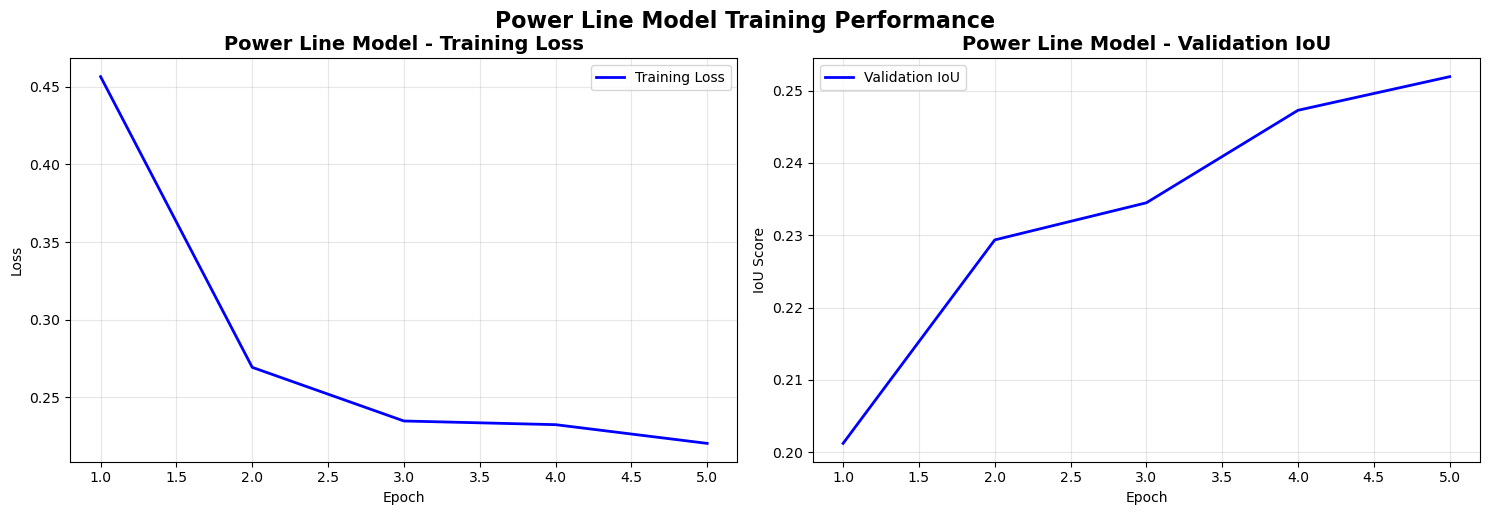

TRAINING SUMMARY
Final Training Loss: 0.2204
Best Validation IoU: 0.2519
Final Validation IoU: 0.2519
Total Epochs: 5


In [11]:
def plot_training_history(history):
    """
    Plot training loss and validation IoU curves
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    epochs = range(1, len(history['train_loss']) + 1)
    
    # Training loss
    ax1.plot(epochs, history['train_loss'], 'b-', linewidth=2, label='Training Loss')
    ax1.set_title('Power Line Model - Training Loss', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Validation IoU
    ax2.plot(epochs, history['val_iou'], 'b-', linewidth=2, label='Validation IoU')
    ax2.set_title('Power Line Model - Validation IoU', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('IoU Score')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.tight_layout()
    plt.suptitle('Power Line Model Training Performance', fontsize=16, fontweight='bold', y=1.02)
    plt.show()
    
    print("TRAINING SUMMARY")
    print("="*50)
    print(f"Final Training Loss: {history['train_loss'][-1]:.4f}")
    print(f"Best Validation IoU: {max(history['val_iou']):.4f}")
    print(f"Final Validation IoU: {history['val_iou'][-1]:.4f}")
    print(f"Total Epochs: {len(history['train_loss'])}")

# Plot training history
plot_training_history(training_history)

## 12. Loss Function Analysis

\n======================================================================
POWER LINE MODEL PREDICTIONS VISUALIZATION


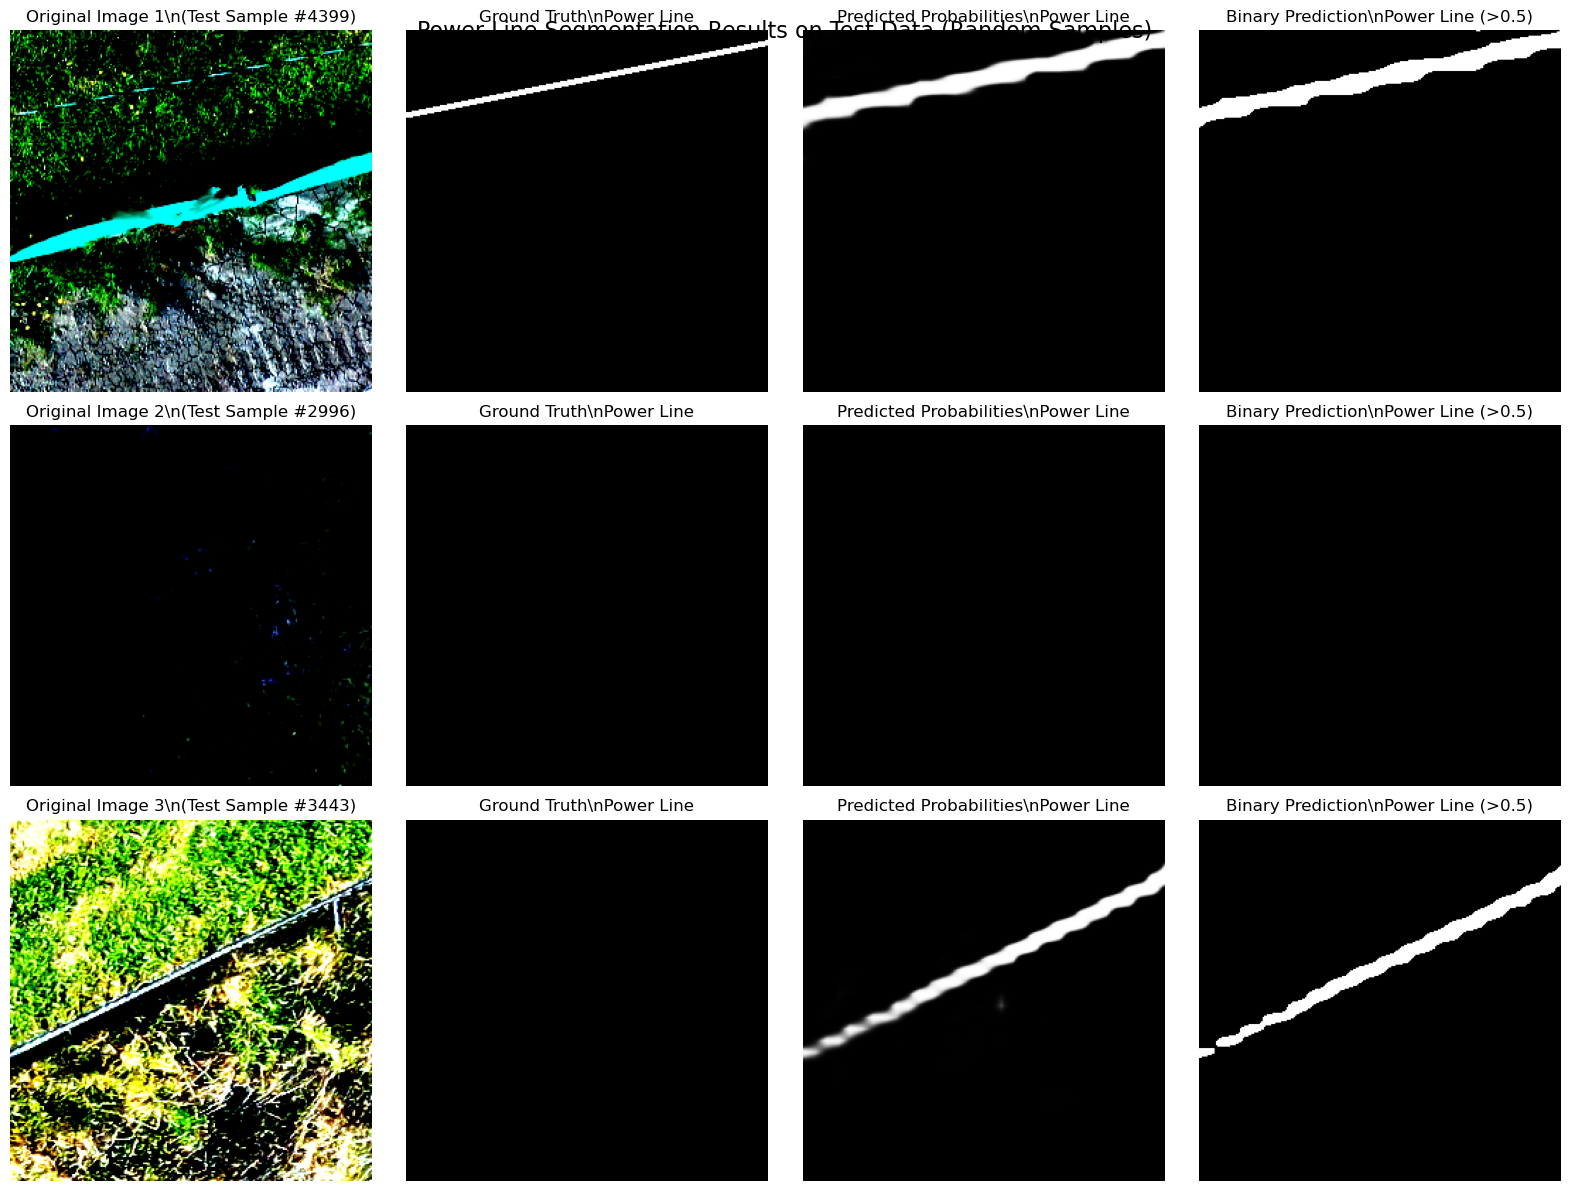

Visualized 3 random power line segmentation examples
Random test sample indices: [4399, 2996, 3443]
\nPower line model visualization completed!


In [14]:
def visualize_tversky_loss():
    """
    Visualize the Tversky loss function behavior
    """
    x = np.linspace(0.001, 0.999, 1000)  # Avoid exact 0 and 1 for numerical stability
    
    # Tversky Loss simulation
    alpha, beta = TVERSKY_ALPHA, TVERSKY_BETA
    tversky_loss = 1 - x / (x + alpha*(1-x) + beta*(1-x))
    
    # Compare with standard Dice loss (alpha=0.5, beta=0.5)
    dice_loss = 1 - x / (x + 0.5*(1-x) + 0.5*(1-x))
    
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    
    ax.plot(x, tversky_loss, 'b-', linewidth=3, label=f'Tversky Loss (α={alpha}, β={beta})')
    ax.plot(x, dice_loss, 'r--', linewidth=2, label='Dice Loss (α=0.5, β=0.5)')
    ax.set_title('Tversky Loss vs Dice Loss Comparison', fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted Probability')
    ax.set_ylabel('Loss Value')
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_ylim(0, 1)
    
    plt.tight_layout()
    plt.show()
    
    print("Tversky Loss Analysis:")
    print("="*40)
    print(f"α={alpha} (false positive weight) - Lower value reduces penalty for false positives")
    print(f"β={beta} (false negative weight) - Higher value increases penalty for missed detections")
    print("This configuration prioritizes recall over precision for power line detection")
    print("Missing a power line (false negative) is more critical than a false detection")

# Visualize loss function
# visualize_tversky_loss()

# Import random for visualization
import random

def visualize_predictions(model, test_loader, num_samples=4, device="cpu"):
    """
    Visualize power line model predictions vs ground truth for a given number of samples
    
    Args:
        model: Trained segmentation model
        test_loader: DataLoader with test data
        num_samples: Number of samples to visualize
        device: Computing device
    """
    model.eval()
    
    # Get all data from the test loader
    all_images = []
    all_masks = []
    
    with torch.no_grad():
        for images, masks in test_loader:
            for i in range(images.shape[0]):
                all_images.append(images[i])
                all_masks.append(masks[i])
    
    # Randomly select samples
    total_samples = len(all_images)
    random_indices = random.sample(range(total_samples), min(num_samples, total_samples))
    
    # Set up the plot
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4*num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)
    
    for sample_idx, data_idx in enumerate(random_indices):
        # Get the randomly selected image and mask
        image = all_images[data_idx].to(device).unsqueeze(0)  # Add batch dimension
        mask = all_masks[data_idx].to(device).unsqueeze(0)    # Add batch dimension
        
        # Get predictions
        prediction = model(image)
        prediction_prob = torch.sigmoid(prediction)
        predicted_mask = (prediction_prob > 0.5).float()
        
        # Convert tensors to numpy for visualization
        image_np = image.squeeze().cpu().detach().permute(1, 2, 0).numpy()
        true_mask_np = mask.squeeze().cpu().detach().numpy()
        pred_mask_np = predicted_mask.squeeze().detach().cpu().numpy()
        prob_mask_np = prediction_prob.squeeze().detach().cpu().numpy()
        
        # Denormalize image for display (since we normalized to [0,1])
        image_np = np.clip(image_np, 0, 1)
        
        # Plot original image
        axes[sample_idx, 0].imshow(image_np)
        axes[sample_idx, 0].set_title(f'Original Image {sample_idx+1}\\n(Test Sample #{data_idx})', fontsize=12)
        axes[sample_idx, 0].axis('off')
        
        # Plot ground truth mask
        axes[sample_idx, 1].imshow(true_mask_np, cmap='gray', vmin=0, vmax=1)
        axes[sample_idx, 1].set_title(f'Ground Truth\\nPower Line', fontsize=12)
        axes[sample_idx, 1].axis('off')
        
        # Plot prediction probabilities
        axes[sample_idx, 2].imshow(prob_mask_np, cmap='gray', vmin=0, vmax=1)
        axes[sample_idx, 2].set_title(f'Predicted Probabilities\\nPower Line', fontsize=12)
        axes[sample_idx, 2].axis('off')
        
        # Plot binary prediction
        axes[sample_idx, 3].imshow(pred_mask_np, cmap='gray', vmin=0, vmax=1)
        axes[sample_idx, 3].set_title(f'Binary Prediction\\nPower Line (>0.5)', fontsize=12)
        axes[sample_idx, 3].axis('off')
    
    plt.tight_layout()
    plt.suptitle('Power Line Segmentation Results on Test Data (Random Samples)', fontsize=16, y=0.98)
    plt.show()
    
    print(f"Visualized {len(random_indices)} random power line segmentation examples")
    print(f"Random test sample indices: {random_indices}")

# Execute power line model visualization
print("\\n" + "="*70)
print("POWER LINE MODEL PREDICTIONS VISUALIZATION")
print("="*70)

visualize_predictions(model, test_loader, num_samples=3, device=DEVICE)

print("\\nPower line model visualization completed!")
print("="*70)